Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded from: /content/drive/MyDrive/Cancer.csv
Dataset shape: (569, 33)

Number of input features: 30
Number of samples: 569

Class distribution:
Benign: 357
Malignant: 212

Training samples: 455
Testing samples: 114
Internal training samples: 364
Validation samples: 91

Neural Network Architecture:
Sequential(
  (0): Linear(in_features=30, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=1, bias=True)
)
Epoch   1 | Train Loss: 0.714779 | Val Loss: 0.713447 | Train Acc: 0.3571 | Val Acc: 0.3516
Epoch  25 | Train Loss: 0.588505 | Val Loss: 0.589015 | Train Acc: 0.9368 | Val Acc: 0.9451
Epoch  50 | Train Loss: 0.372507 | Val Loss: 0.377006 | Train Acc: 0.9560 | Val Acc: 0.9451
Epoch  75 | Train Loss: 0.188460 | Val Loss: 0.200407 | Train Acc: 0.96

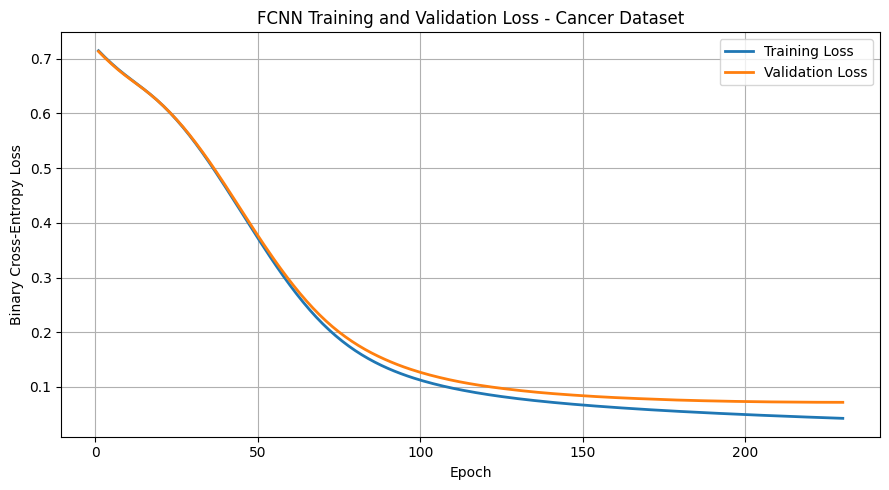

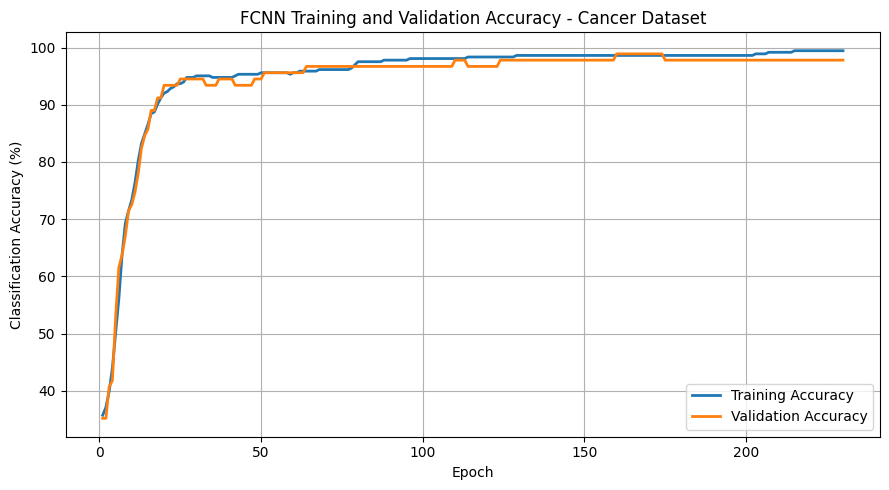


========== PROBLEM 2.a ==========

Neural Network Architecture:
Sequential(
  (0): Linear(in_features=30, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=1, bias=True)
)

Hyperparameters:
Input features: 30
Hidden layers: 2
Hidden neurons: 32, 16
Hidden activation: ReLU
Output: 1 binary logit
Prediction activation: Sigmoid
Loss function: Binary Cross-Entropy
Optimizer: Adam
Learning rate: 0.001
Epochs: 230
Training method: Full-batch gradient updates
Early stopping: Not used

FCNN Test Performance:
Accuracy:  0.9825
Precision: 1.0000
Recall:    0.9524
F1 Score:  0.9756


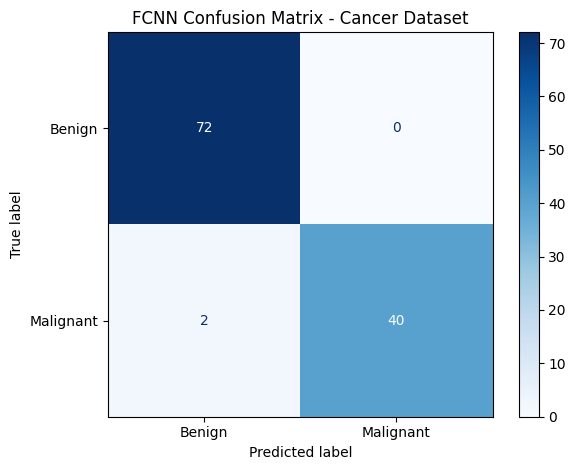


========== PROBLEM 2.b ==========

Test Classification Performance:
                     Accuracy  Precision  Recall  F1 Score
Model                                                     
FCNN                   0.9825     1.0000  0.9524    0.9756
Logistic Regression    0.9649     0.9750  0.9286    0.9512
SVM                    0.9737     1.0000  0.9286    0.9630

Best model(s) based on F1 Score: FCNN


In [3]:

# ============================================================
# HOMEWORK 6 - PROBLEM 2: BREAST CANCER CLASSIFICATION
# Problem 2.a: Fully Connected Neural Network
# Problem 2.b: Comparison with Logistic Regression and SVM
#

# ============================================================

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ============================================================
# 2. MOUNT GOOGLE DRIVE AND LOAD CANCER DATASET
# ============================================================

drive.mount('/content/drive')

file_path = None

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.lower() == 'cancer.csv':
            file_path = os.path.join(root, file)
            break

    if file_path is not None:
        break

if file_path is None:
    raise FileNotFoundError(
        "Cancer.csv not found in Google Drive."
    )

df = pd.read_csv(file_path)

print("Dataset loaded from:", file_path)
print("Dataset shape:", df.shape)


# ============================================================
# 3. SET RANDOM SEED
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


# ============================================================
# 4. PREPARE INPUT FEATURES AND TARGET
# ============================================================

# Remove non-predictive columns.
# Use all 30 actual cancer measurement features.

X = df.drop(
    columns=['id', 'diagnosis', 'Unnamed: 32'],
    errors='ignore'
)

# Same labeling convention as Homework 3:
# 0 = Benign
# 1 = Malignant

y = df['diagnosis'].map({
    'B': 0,
    'M': 1
}).values

print("\nNumber of input features:", X.shape[1])
print("Number of samples:", len(X))

print("\nClass distribution:")
print("Benign:", np.sum(y == 0))
print("Malignant:", np.sum(y == 1))

assert X.shape[1] == 30, "Expected exactly 30 input features."


# ============================================================
# 5. TRAINING AND TESTING SPLIT (80% / 20%)
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Internal validation comes only from training data.
# Test data is reserved for final evaluation.

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Internal training samples:", len(X_fit))
print("Validation samples:", len(X_val))


# ============================================================
# 6. INPUT STANDARDIZATION
# ============================================================

# Fit scaler only on internal training data.

scaler_val = StandardScaler()

X_fit_scaled = scaler_val.fit_transform(X_fit)
X_val_scaled = scaler_val.transform(X_val)


# ============================================================
# PROBLEM 2.a: FULLY CONNECTED NEURAL NETWORK
# ============================================================

# ============================================================
# 7. CONVERT DATA TO PYTORCH TENSORS
# ============================================================

X_fit_tensor = torch.tensor(
    X_fit_scaled,
    dtype=torch.float32
)

y_fit_tensor = torch.tensor(
    y_fit.reshape(-1, 1),
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val_scaled,
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val.reshape(-1, 1),
    dtype=torch.float32
)


# ============================================================
# 8. DEFINE FULLY CONNECTED NEURAL NETWORK
# ============================================================

# Input: 30 features
# Hidden layer 1: 32 neurons, ReLU
# Hidden layer 2: 16 neurons, ReLU
# Output: 1 neuron (binary classification logit)
#
# BCEWithLogitsLoss applies sigmoid internally for training.
# Sigmoid is used for predicted probabilities during evaluation.

def create_model(input_size):

    model = nn.Sequential(
        nn.Linear(input_size, 32),
        nn.ReLU(),

        nn.Linear(32, 16),
        nn.ReLU(),

        nn.Linear(16, 1)
    )

    return model


input_size = X_fit_tensor.shape[1]

model = create_model(input_size)

print("\nNeural Network Architecture:")
print(model)


# ============================================================
# 9. LOSS FUNCTION AND OPTIMIZER
# ============================================================

learning_rate = 0.001
num_epochs = 230

# Binary cross-entropy loss with built-in sigmoid operation.
loss_fn = nn.BCEWithLogitsLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate
)


# ============================================================
# 10. TRAINING AND VALIDATION LOOP
# ============================================================

# Fixed-epoch training following Dr. Tabkhi's lecture style.
# No early stopping.
# Validation data is never used for gradient updates.

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

for epoch in range(1, num_epochs + 1):

    # Training mode
    model.train()

    # Forward pass
    train_logits = model(X_fit_tensor)

    # Calculate training loss
    train_loss = loss_fn(
        train_logits,
        y_fit_tensor
    )

    # Backpropagation
    optimizer.zero_grad()

    train_loss.backward()

    # Update parameters
    optimizer.step()

    # Evaluation mode
    model.eval()

    with torch.no_grad():

        # Training predictions after parameter update
        train_logits = model(X_fit_tensor)

        train_loss = loss_fn(
            train_logits,
            y_fit_tensor
        )

        # Validation predictions
        val_logits = model(X_val_tensor)

        val_loss = loss_fn(
            val_logits,
            y_val_tensor
        )

        # Convert logits to probabilities
        train_probabilities = torch.sigmoid(train_logits)
        val_probabilities = torch.sigmoid(val_logits)

        # Threshold at 0.5 for binary classification
        train_predictions = (
            train_probabilities >= 0.5
        ).float()

        val_predictions = (
            val_probabilities >= 0.5
        ).float()

        # Classification accuracy
        train_accuracy = (
            train_predictions == y_fit_tensor
        ).float().mean().item()

        val_accuracy = (
            val_predictions == y_val_tensor
        ).float().mean().item()

    # Store results
    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    # Print training progress
    if epoch == 1 or epoch % 25 == 0:

        print(
            f"Epoch {epoch:3d} | "
            f"Train Loss: {train_loss.item():.6f} | "
            f"Val Loss: {val_loss.item():.6f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Acc: {val_accuracy:.4f}"
        )


# ============================================================
# 11. PLOT TRAINING AND VALIDATION LOSSES
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, num_epochs + 1),
    train_losses,
    label='Training Loss',
    linewidth=2
)

plt.plot(
    range(1, num_epochs + 1),
    val_losses,
    label='Validation Loss',
    linewidth=2
)

plt.xlabel('Epoch')
plt.ylabel('Binary Cross-Entropy Loss')
plt.title('FCNN Training and Validation Loss - Cancer Dataset')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 12. PLOT TRAINING AND VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, num_epochs + 1),
    np.array(train_accuracies) * 100,
    label='Training Accuracy',
    linewidth=2
)

plt.plot(
    range(1, num_epochs + 1),
    np.array(val_accuracies) * 100,
    label='Validation Accuracy',
    linewidth=2
)

plt.xlabel('Epoch')
plt.ylabel('Classification Accuracy (%)')
plt.title('FCNN Training and Validation Accuracy - Cancer Dataset')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 13. TRAIN FINAL FCNN ON ALL 80% TRAINING DATA
# ============================================================

# Refit StandardScaler on all training samples only.

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_tensor = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train.reshape(-1, 1),
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

# Initialize fresh neural network.

torch.manual_seed(SEED)

final_model = create_model(X_train_tensor.shape[1])

final_optimizer = optim.Adam(
    final_model.parameters(),
    lr=learning_rate
)

# Train for same fixed number of epochs.

for epoch in range(1, num_epochs + 1):

    final_model.train()

    # Forward pass
    logits = final_model(X_train_tensor)

    # Binary cross-entropy loss
    loss = loss_fn(
        logits,
        y_train_tensor
    )

    # Backpropagation
    final_optimizer.zero_grad()

    loss.backward()

    # Parameter update
    final_optimizer.step()


# ============================================================
# 14. FCNN TEST PREDICTIONS
# ============================================================

final_model.eval()

with torch.no_grad():

    test_logits = final_model(X_test_tensor)

    test_probabilities = torch.sigmoid(
        test_logits
    ).numpy().ravel()

# Predict malignant if probability >= 0.5.

y_pred_fcnn = (
    test_probabilities >= 0.5
).astype(int)


# ============================================================
# 15. FCNN CLASSIFICATION METRICS
# ============================================================

fcnn_accuracy = accuracy_score(
    y_test,
    y_pred_fcnn
)

fcnn_precision = precision_score(
    y_test,
    y_pred_fcnn,
    pos_label=1,
    zero_division=0
)

fcnn_recall = recall_score(
    y_test,
    y_pred_fcnn,
    pos_label=1,
    zero_division=0
)

fcnn_f1 = f1_score(
    y_test,
    y_pred_fcnn,
    pos_label=1,
    zero_division=0
)

print("\n========== PROBLEM 2.a ==========")

print("\nNeural Network Architecture:")
print(final_model)

print("\nHyperparameters:")
print("Input features: 30")
print("Hidden layers: 2")
print("Hidden neurons: 32, 16")
print("Hidden activation: ReLU")
print("Output: 1 binary logit")
print("Prediction activation: Sigmoid")
print("Loss function: Binary Cross-Entropy")
print("Optimizer: Adam")
print("Learning rate:", learning_rate)
print("Epochs:", num_epochs)
print("Training method: Full-batch gradient updates")
print("Early stopping: Not used")

print("\nFCNN Test Performance:")
print(f"Accuracy:  {fcnn_accuracy:.4f}")
print(f"Precision: {fcnn_precision:.4f}")
print(f"Recall:    {fcnn_recall:.4f}")
print(f"F1 Score:  {fcnn_f1:.4f}")


# ============================================================
# 16. PLOT FCNN CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred_fcnn,
    labels=[0, 1]
)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Benign', 'Malignant']
)

display_cm.plot(
    cmap='Blues',
    values_format='d'
)

plt.title('FCNN Confusion Matrix - Cancer Dataset')
plt.tight_layout()
plt.show()


# ============================================================
# PROBLEM 2.b: TRADITIONAL MACHINE LEARNING COMPARISON
# ============================================================

# ============================================================
# 17. LOGISTIC REGRESSION
# ============================================================

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

y_pred_logistic = logistic_model.predict(
    X_test_scaled
)


# ============================================================
# 18. SUPPORT VECTOR MACHINE (SVM)
# ============================================================

svm_model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale'
)

svm_model.fit(
    X_train_scaled,
    y_train
)

y_pred_svm = svm_model.predict(
    X_test_scaled
)


# ============================================================
# 19. EVALUATION METRICS
# ============================================================

# Malignant (1) is the positive class for all models.

def evaluate_model(y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    return {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    }


# ============================================================
# 20. COMPARE ALL THREE MODELS
# ============================================================

results = pd.DataFrame({

    'FCNN': evaluate_model(
        y_test,
        y_pred_fcnn
    ),

    'Logistic Regression': evaluate_model(
        y_test,
        y_pred_logistic
    ),

    'SVM': evaluate_model(
        y_test,
        y_pred_svm
    )

}).T

results.index.name = 'Model'

print("\n========== PROBLEM 2.b ==========")

print("\nTest Classification Performance:")

print(
    results.to_string(
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# 21. IDENTIFY BEST MODEL
# ============================================================

# F1 score is used for ranking the models.
# Accuracy, precision, and recall are also reported.

best_f1 = results['F1 Score'].max()

best_models = results.index[
    np.isclose(results['F1 Score'], best_f1)
].tolist()

print("\nBest model(s) based on F1 Score:", ", ".join(best_models))

fcnn_best = (
    results.loc['FCNN', 'F1 Score']
    > results.loc[
        ['Logistic Regression', 'SVM'],
        'F1 Score'
    ].max()
)


